# Chest X-Ray Multi-Label — Recall-Boost (single model)
**One DenseNet121 model** focused on raising recall. Every output is uploaded to the Drive folder
`16KKMb0TcYZGKE2Kf4cqAbCkAbXEcyD07`.

**What changed vs. the previous notebook**

| # | Change | Why it raises recall |
|---|--------|----------------------|
| 1 | **Recall-oriented thresholds** (F2 or a minimum-recall target, tuned per class on validation) instead of F1-max | F1-max picked thresholds of 0.54–0.89, cutting recall from 0.54 to 0.38 |
| 2 | **Weighted focal loss** (class weights + γ=2) | Focuses training on hard / missed positives instead of easy negatives |
| 3 | **No double augmentation**: online augmentation only on original images; offline `_aug_` images pass through untouched | Stops over-distorting the rare-class images so lesions stay visible |
| 4 | Reports **Recall, Precision, F1, ROC-AUC and PR-AUC**, plus before/after recall per class | Shows the trade-off honestly |

Runtime: **GPU**. If `run3_finetuned.keras` exists it is used as the starting point (fast); otherwise the model is trained from ImageNet weights.

## 1. Setup

In [1]:
from google.colab import drive, auth
drive.mount('/content/drive')
auth.authenticate_user()          # needed to upload outputs to the shared Drive folder

Mounted at /content/drive


In [2]:
%pip install -q mlflow

In [3]:
import os, json, random, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import mlflow
from IPython.display import display
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve)

# ---------------- Paths ----------------
PROJECT_DIR = Path("/content/drive/MyDrive/x_ray_ds")   # zips, csv files, old models, mlflow.db
DATA_ROOT   = Path("/content/chest_xray_512_merged")
EXTRA_DIR   = Path("/content/images_5_6")
OLD_MODEL_DIR = PROJECT_DIR / "models"
INIT_CANDIDATES = [OLD_MODEL_DIR / "run3_finetuned.keras", OLD_MODEL_DIR / "run2_fixed_frozen.keras"]

OUT_DIR = Path("/content/outputs_recall_boost"); OUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_FOLDER_ID = "16KKMb0TcYZGKE2Kf4cqAbCkAbXEcyD07"     # all outputs are uploaded here

MODEL_PATH  = OUT_DIR / "recall_boost_densenet121.keras"
CONFIG_PATH = OUT_DIR / "inference_config_recall.json"

# ---------------- Settings ----------------
EXCLUDED_CLASSES = {"Hernia"}
IMG_SIZE, BATCH_SIZE = 224, 32
EPOCHS          = 10        # early stopping usually ends sooner
LR_FINETUNE     = 5e-5      # lower than before: we start from an already-trained model
FOCAL_GAMMA     = 2.0
POS_WEIGHT_CAP  = 20.0

THRESHOLD_MODE  = "f2"      # "f2"  -> maximise F2 (recall counts 2x precision)
                            # "recall_target" -> lowest-cost threshold reaching TARGET_RECALL
TARGET_RECALL   = 0.75

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "NOT FOUND - switch the runtime to a GPU")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Drive upload helper
Uploads (or overwrites, if the name already exists) a file into the Drive folder.

In [4]:
from googleapiclient.discovery import build as gbuild
from googleapiclient.http import MediaFileUpload

drive_service = gbuild("drive", "v3")

def upload_to_drive(path, folder_id=DRIVE_FOLDER_ID):
    path = Path(path)
    q = f"name = '{path.name}' and '{folder_id}' in parents and trashed = false"
    found = drive_service.files().list(q=q, fields="files(id)", supportsAllDrives=True,
                                       includeItemsFromAllDrives=True).execute().get("files", [])
    media = MediaFileUpload(str(path), resumable=True)
    if found:
        drive_service.files().update(fileId=found[0]["id"], media_body=media,
                                     supportsAllDrives=True).execute()
        print("Updated on Drive:", path.name)
    else:
        drive_service.files().create(body={"name": path.name, "parents": [folder_id]},
                                     media_body=media, fields="id", supportsAllDrives=True).execute()
        print("Uploaded to Drive:", path.name)

def save_fig(fig, name):
    p = OUT_DIR / name
    fig.savefig(p, dpi=150, bbox_inches="tight")
    upload_to_drive(p)

# quick permission check
_t = OUT_DIR / "_drive_access_check.txt"; _t.write_text("ok")
upload_to_drive(_t)

Uploaded to Drive: _drive_access_check.txt


## 2. Extract the data

In [5]:
def extract_once(zip_path, dest, check_path):
    if check_path.exists():
        print(f"Already extracted: {check_path}"); return
    print(f"Extracting {zip_path.name} ... (takes a few minutes)")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    print("Done.")

extract_once(PROJECT_DIR / "archive (1).zip", Path("/content"), DATA_ROOT)
extract_once(PROJECT_DIR / "images_5_6.zip", EXTRA_DIR, EXTRA_DIR)

IMG_EXT = {".png", ".jpg", ".jpeg"}
image_index = {p.name: str(p) for root in (DATA_ROOT, EXTRA_DIR)
               for p in root.rglob("*") if p.suffix.lower() in IMG_EXT}
print("Images found on disk:", len(image_index))

Extracting archive (1).zip ... (takes a few minutes)
Done.
Extracting images_5_6.zip ... (takes a few minutes)
Done.
Images found on disk: 37545


## 3. Train / validation / test tables

In [6]:
def clean_labels(s):
    if pd.isna(s):
        return []
    return [l.strip() for l in str(s).split("|") if l.strip() and l.strip() not in EXCLUDED_CLASSES]

def patient_from_name(name):
    head = str(name).split("_")[0]
    return int(head) if head.isdigit() else -1

def prepare(df, name):
    df = df.copy()
    df["Image Index"] = df["Image Index"].astype(str).str.strip()
    df = df.drop_duplicates("Image Index")
    df["image_path"]  = df["Image Index"].map(image_index)
    df["patient"]     = df["Image Index"].map(patient_from_name)
    df["labels_list"] = df["Finding Labels"].apply(clean_labels)
    df["is_offline_aug"] = df["Image Index"].str.contains("_aug", case=False)
    df = df[df["image_path"].notna() & (df["labels_list"].str.len() > 0)].reset_index(drop=True)
    print(f"{name:<10} {len(df):>6} images | offline-augmented: {int(df['is_offline_aug'].sum())}")
    return df

train_df = prepare(pd.read_csv(PROJECT_DIR / "combined.csv"), "train")
val_df   = prepare(pd.read_csv(DATA_ROOT / "validation" / "validation.csv"), "validation")
test_df  = prepare(pd.read_csv(DATA_ROOT / "test" / "test.csv"), "test")

held_out = (set(val_df["patient"]) | set(test_df["patient"])) - {-1}
leak = train_df["patient"].isin(held_out)
train_df = train_df[~leak].reset_index(drop=True)
print("Leaked train images removed:", int(leak.sum()), "| final train size:", len(train_df))

train       26530 images | offline-augmented: 4376
validation   5646 images | offline-augmented: 0
test         5369 images | offline-augmented: 0
Leaked train images removed: 0 | final train size: 26530


## 4. Labels

In [7]:
mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(train_df["labels_list"]).astype("float32")
y_val   = mlb.transform(val_df["labels_list"]).astype("float32")
y_test  = mlb.transform(test_df["labels_list"]).astype("float32")
classes = list(mlb.classes_); NUM_CLASSES = len(classes)

dist = pd.DataFrame({"train %": 100 * y_train.mean(0), "val %": 100 * y_val.mean(0),
                     "test %": 100 * y_test.mean(0)}, index=classes).round(1)
display(dist.sort_values("train %", ascending=False))

,train %,val %,test %
Infiltration,29.500000,15.300000,14.1
No Finding,18.799999,55.799999,60.0
Atelectasis,18.600000,9.400000,9.4
Effusion,17.000000,10.600000,9.4
Mass,10.400000,3.900000,3.7
Consolidation,9.500000,3.500000,3.5
Nodule,9.500000,4.800000,5.3
Pneumothorax,7.500000,6.000000,3.4
Pleural_Thickening,7.200000,3.300000,2.8
Cardiomegaly,5.200000,4.300000,2.4


## 5. Input pipeline — augmentation only on original images
`combined.csv` already contains offline-augmented copies (`*_aug_*`). Those images now skip online
augmentation, so no image is augmented twice. Online augmentation is also slightly lighter.

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    return tf.image.resize(img, [IMG_SIZE, IMG_SIZE]) / 255.0

def light_aug(img):
    img = tf.image.random_brightness(img, 0.08)
    img = tf.image.random_contrast(img, 0.92, 1.08)
    # random zoom-in / shift: crop 90-100% of the image, resize back
    scale = tf.random.uniform([], 0.90, 1.0)
    size  = tf.cast(scale * IMG_SIZE, tf.int32)
    img   = tf.image.random_crop(img, [size, size, 3])
    img   = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return tf.clip_by_value(img, 0.0, 1.0)

def make_ds(df, labels, training):
    flags = df["is_offline_aug"].values.astype(bool)
    ds = tf.data.Dataset.from_tensor_slices((df["image_path"].values, labels, flags))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    def _map(path, label, already_aug):
        img = load_image(path)
        if training:
            img = tf.cond(already_aug, lambda: img, lambda: light_aug(img))
        return img, label
    return ds.map(_map, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, y_train, training=True)
val_ds   = make_ds(val_df,   y_val,   training=False)
test_ds  = make_ds(test_df,  y_test,  training=False)

imgs, labs = next(iter(train_ds))
print("Batch:", imgs.shape, "| range:", float(tf.reduce_min(imgs)), "-", float(tf.reduce_max(imgs)))

Batch: (32, 224, 224, 3) | range: 0.0 - 1.0


## 6. Model and weighted focal loss
Focal loss down-weights easy examples (`(1-p)^γ`), so the model spends its capacity on positives it is
still missing. Class weights (`neg/pos`, capped at 20) are kept on top.

In [9]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import DenseNet121

def build_model():
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="xray_image")
    x = layers.Normalization(mean=[0.485, 0.456, 0.406],
                             variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2], name="imagenet_norm")(inputs)
    base = DenseNet121(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="sigmoid", name="disease_probabilities")(x)
    return Model(inputs, outputs, name="xray_densenet121")

pos_counts = y_train.sum(axis=0)
pos_weight = np.clip((len(y_train) - pos_counts) / np.maximum(pos_counts, 1), 1.0, POS_WEIGHT_CAP)
POS_WEIGHT = tf.constant(pos_weight, dtype=tf.float32)

def weighted_focal_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    p = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    pos = -POS_WEIGHT * y_true * tf.pow(1.0 - p, FOCAL_GAMMA) * tf.math.log(p)
    neg = -(1.0 - y_true) * tf.pow(p, FOCAL_GAMMA) * tf.math.log(1.0 - p)
    return tf.reduce_mean(pos + neg, axis=-1)

def set_backbone_trainable(model, trainable):
    base = next(l for l in model.layers if isinstance(l, tf.keras.Model))
    base.trainable = trainable
    if trainable:
        for l in base.layers:                       # BatchNorm stays frozen
            if isinstance(l, tf.keras.layers.BatchNormalization):
                l.trainable = False

def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss=weighted_focal_loss,
                  metrics=[tf.keras.metrics.AUC(multi_label=True, num_labels=NUM_CLASSES, name="macro_auc"),
                           tf.keras.metrics.AUC(curve="PR", multi_label=True, num_labels=NUM_CLASSES, name="macro_pr_auc"),
                           tf.keras.metrics.Recall(name="recall_at_05")])

## 7. Train the single model

In [10]:
mlflow.set_tracking_uri(f"sqlite:///{PROJECT_DIR / 'mlflow.db'}")
mlflow.set_experiment("Chest_XRay_MultiLabel")

class MLflowMetricsCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        for k, v in (logs or {}).items():
            try: mlflow.log_metric(k, float(v), step=epoch + 1)
            except (TypeError, ValueError): pass

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(str(MODEL_PATH), monitor="val_macro_auc", mode="max",
                                       save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_macro_auc", mode="max", factor=0.3,
                                         patience=1, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_macro_auc", mode="max", patience=3,
                                     restore_best_weights=True, verbose=1),
    MLflowMetricsCallback(),
]

tf.keras.backend.clear_session()
init_path = next((p for p in INIT_CANDIDATES if p.exists()), None)

with mlflow.start_run(run_name="Run4_recall_boost") as run:
    histories = []
    if init_path is not None:
        print("Starting from:", init_path.name)
        model = tf.keras.models.load_model(init_path, compile=False)
    else:
        print("No checkpoint found - warming up the head on frozen ImageNet DenseNet121")
        model = build_model()
        set_backbone_trainable(model, False)
        compile_model(model, 1e-3)
        histories.append(model.fit(train_ds, validation_data=val_ds, epochs=3,
                                   callbacks=[MLflowMetricsCallback()]))

    set_backbone_trainable(model, True)
    compile_model(model, LR_FINETUNE)
    mlflow.log_params({"model": "DenseNet121", "loss": "weighted_focal", "focal_gamma": FOCAL_GAMMA,
                       "pos_weight_cap": POS_WEIGHT_CAP, "lr": LR_FINETUNE, "max_epochs": EPOCHS,
                       "augmentation": "light, original images only (offline _aug_ skipped)",
                       "init_weights": init_path.name if init_path else "imagenet",
                       "threshold_mode": THRESHOLD_MODE, "target_recall": TARGET_RECALL,
                       "img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "train_images": len(train_df)})
    histories.append(model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks))
    RUN_ID = run.info.run_id

model.save(MODEL_PATH)          # best weights (restore_best_weights=True)
upload_to_drive(MODEL_PATH)

Starting from: run3_finetuned.keras
Epoch 1/10
830/830 ━━━━━━━━━━━━━━━━━━━━ 0s 363ms/step - loss: 0.2074 - macro_auc: 0.8512 - macro_pr_auc: 0.4458 - recall_at_05: 0.7469
Epoch 1: val_macro_auc improved from None to 0.77106, saving model to /content/outputs_recall_boost/recall_boost_densenet121.keras

Epoch 1: finished saving model to /content/outputs_recall_boost/recall_boost_densenet121.keras
830/830 ━━━━━━━━━━━━━━━━━━━━ 452s 437ms/step - loss: 0.2034 - macro_auc: 0.8535 - macro_pr_auc: 0.4563 - recall_at_05: 0.7471 - val_loss: 0.2051 - val_macro_auc: 0.7711 - val_macro_pr_auc: 0.2305 - val_recall_at_05: 0.6719 - learning_rate: 5.0000e-05
Epoch 2/10
830/830 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - loss: 0.1923 - macro_auc: 0.8664 - macro_pr_auc: 0.4957 - recall_at_05: 0.7584
Epoch 2: val_macro_auc did not improve from 0.77106

Epoch 2: ReduceLROnPlateau reducing learning rate to 1.4999999621068127e-05.
830/830 ━━━━━━━━━━━━━━━━━━━━ 266s 320ms/step - loss: 0.1919 - macro_auc: 0.8666 - macr

Uploaded to Drive: training_history.png


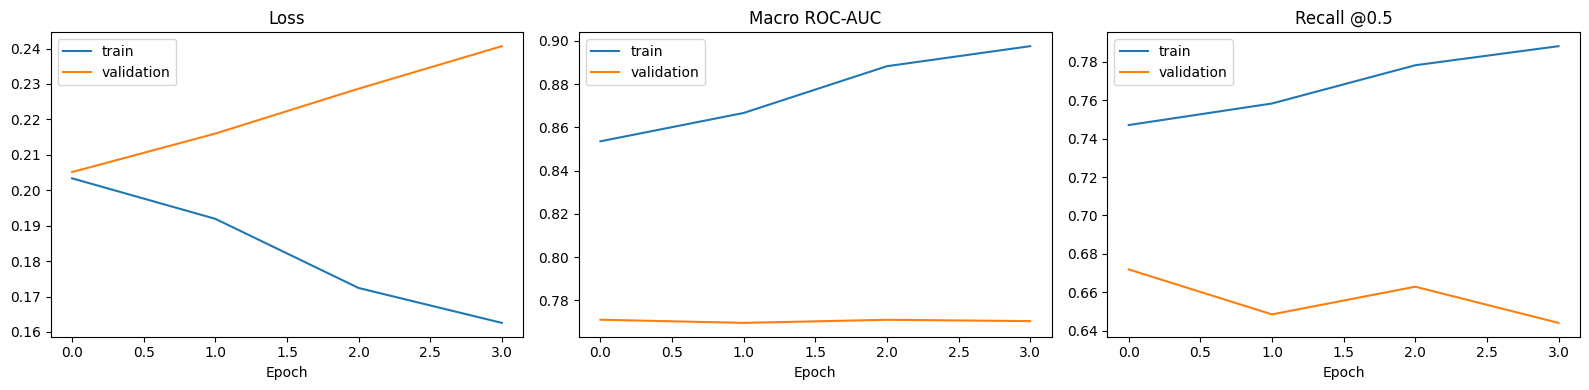

Uploaded to Drive: training_history.csv


In [11]:
h = {k: sum((hh.history.get(k, []) for hh in histories), []) for k in histories[-1].history}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, key, title in zip(axes, ["loss", "macro_auc", "recall_at_05"], ["Loss", "Macro ROC-AUC", "Recall @0.5"]):
    ax.plot(h[key], label="train"); ax.plot(h["val_" + key], label="validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); save_fig(fig, "training_history.png"); plt.show()
pd.DataFrame(h).to_csv(OUT_DIR / "training_history.csv", index_label="epoch")
upload_to_drive(OUT_DIR / "training_history.csv")

## 8. Recall-oriented thresholds (tuned on validation)
Three strategies are compared on the **test** set:
- **F1-max** — what the old notebook used (high thresholds → low recall)
- **F2-max** — recall weighted twice as much as precision
- **Recall ≥ target** — the highest threshold that still reaches `TARGET_RECALL` on validation

`THRESHOLD_MODE` decides which one is saved for the app.

In [12]:
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
val_prob  = model.predict(val_ds, verbose=1)
test_prob = model.predict(test_ds, verbose=1)
np.save(OUT_DIR / "test_probabilities.npy", test_prob)

def thr_fbeta(y, p, beta):
    pr, rc, t = precision_recall_curve(y, p)
    f = (1 + beta**2) * pr * rc / (beta**2 * pr + rc + 1e-8)
    return float(t[np.argmax(f[:-1])])

def thr_recall(y, p, target):
    pr, rc, t = precision_recall_curve(y, p)
    ok = np.where(rc[:-1] >= target)[0]
    return float(t[ok.max()]) if len(ok) else float(t[0])

TH = {
    "0.5":        np.full(NUM_CLASSES, 0.5),
    "F1-max":     np.array([thr_fbeta(y_val[:, i], val_prob[:, i], 1) for i in range(NUM_CLASSES)]),
    "F2-max":     np.array([thr_fbeta(y_val[:, i], val_prob[:, i], 2) for i in range(NUM_CLASSES)]),
    f"Recall>={TARGET_RECALL}": np.array([thr_recall(y_val[:, i], val_prob[:, i], TARGET_RECALL)
                                          for i in range(NUM_CLASSES)]),
}

def per_class_metrics(y_true, prob, th):
    pred = (prob >= th).astype(int)
    return pd.DataFrame([{
        "Disease": c,
        "ROC-AUC": roc_auc_score(y_true[:, i], prob[:, i]),
        "PR-AUC":  average_precision_score(y_true[:, i], prob[:, i]),
        "Recall":    recall_score(y_true[:, i], pred[:, i], zero_division=0),
        "Precision": precision_score(y_true[:, i], pred[:, i], zero_division=0),
        "F1":        f1_score(y_true[:, i], pred[:, i], zero_division=0),
        "Threshold": float(th[i]),
        "Positives": int(y_true[:, i].sum()),
    } for i, c in enumerate(classes)])

results = {name: per_class_metrics(y_test, test_prob, th) for name, th in TH.items()}
summary = pd.DataFrame({n: r[["ROC-AUC", "PR-AUC", "Recall", "Precision", "F1"]].mean()
                        for n, r in results.items()}).T.round(4)
print("TEST SET - macro averages by threshold strategy")
display(summary)
summary.to_csv(OUT_DIR / "test_summary_by_threshold.csv")

all_rows = pd.concat([r.assign(Strategy=n) for n, r in results.items()])
all_rows.to_csv(OUT_DIR / "test_per_class_metrics.csv", index=False)
for f in ["test_summary_by_threshold.csv", "test_per_class_metrics.csv", "test_probabilities.npy"]:
    upload_to_drive(OUT_DIR / f)

177/177 ━━━━━━━━━━━━━━━━━━━━ 58s 246ms/step
168/168 ━━━━━━━━━━━━━━━━━━━━ 45s 268ms/step
TEST SET - macro averages by threshold strategy


,ROC-AUC,PR-AUC,Recall,Precision,F1
0.5,0.7653,0.2265,0.5329,0.1811,0.2492
F1-max,0.7653,0.2265,0.3818,0.2300,0.2765
F2-max,0.7653,0.2265,0.6030,0.1677,0.2479
Recall>=0.75,0.7653,0.2265,0.7257,0.1564,0.2222


Uploaded to Drive: test_summary_by_threshold.csv
Uploaded to Drive: test_per_class_metrics.csv
Uploaded to Drive: test_probabilities.npy


## 9. Plots: recall per class, ROC and PR curves

Uploaded to Drive: recall_per_class_old_vs_new.png


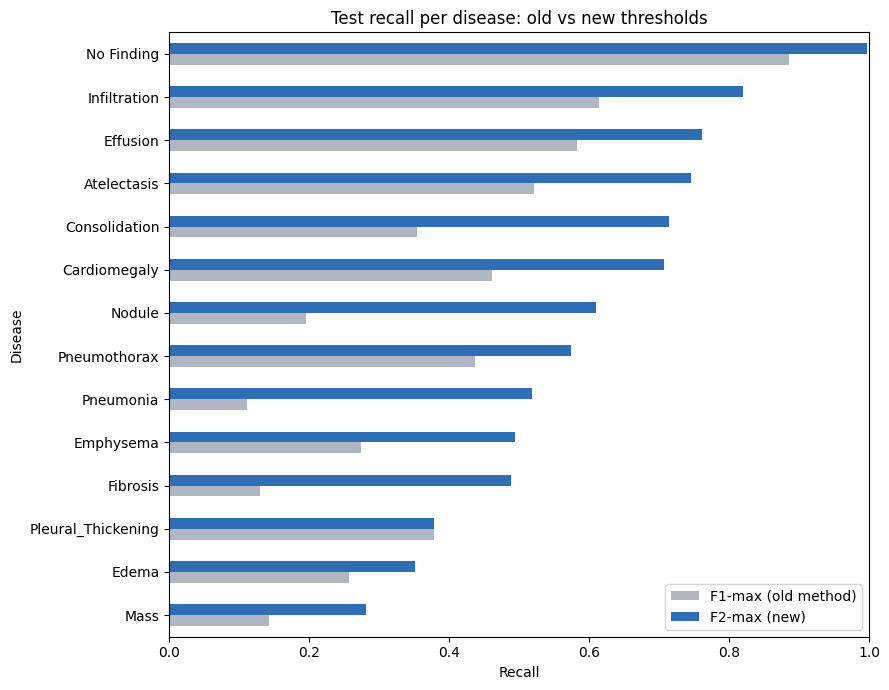

Uploaded to Drive: roc_pr_curves.png


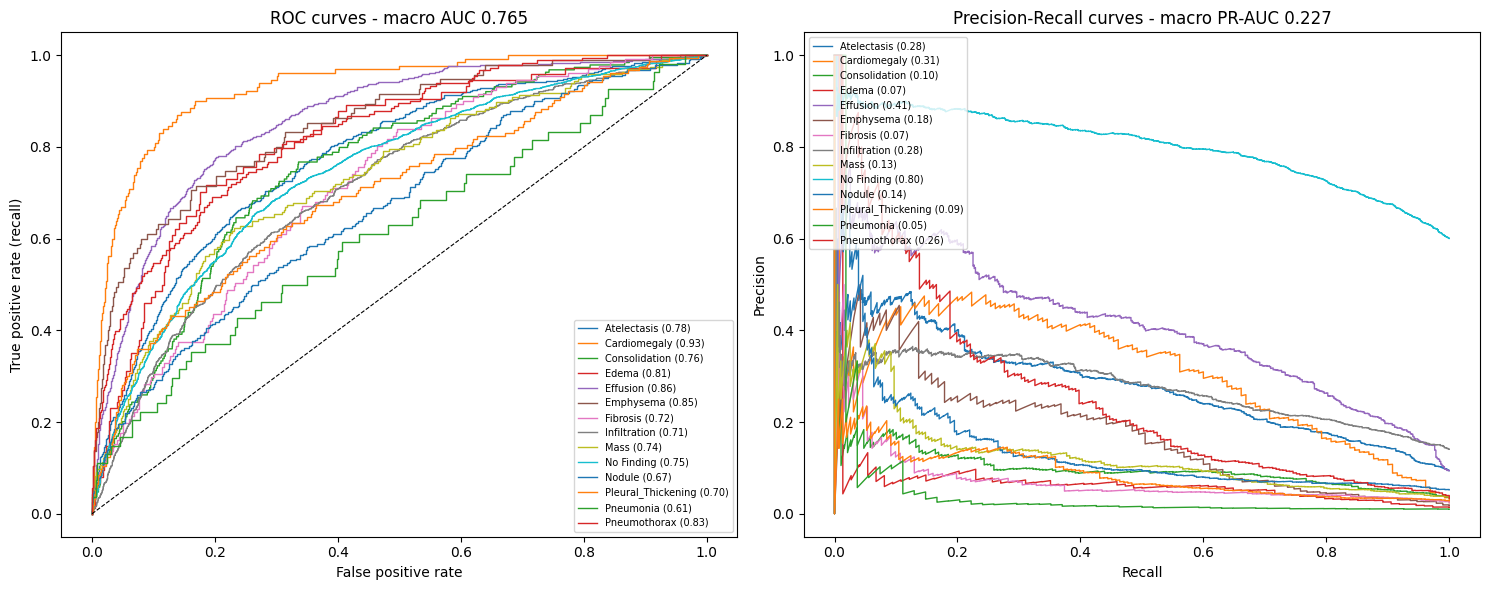

,Disease,ROC-AUC,PR-AUC,Recall,Precision,F1,Threshold,Positives
0,Atelectasis,0.777,0.281,0.745,0.189,0.301,0.481,506
1,Cardiomegaly,0.930,0.314,0.708,0.219,0.334,0.498,130
2,Consolidation,0.757,0.099,0.714,0.080,0.144,0.463,189
3,Edema,0.814,0.072,0.351,0.063,0.107,0.470,74
4,Effusion,0.859,0.409,0.761,0.291,0.421,0.475,506
5,Emphysema,0.850,0.178,0.495,0.184,0.268,0.604,95
6,Fibrosis,0.720,0.074,0.489,0.051,0.092,0.450,131
7,Infiltration,0.713,0.276,0.820,0.201,0.322,0.418,755
8,Mass,0.736,0.125,0.281,0.142,0.188,0.534,196
9,No Finding,0.747,0.801,0.997,0.603,0.751,0.269,3224


In [13]:
chosen = "F2-max" if THRESHOLD_MODE == "f2" else f"Recall>={TARGET_RECALL}"

rec = pd.DataFrame({"F1-max (old method)": results["F1-max"].set_index("Disease")["Recall"],
                    f"{chosen} (new)":     results[chosen].set_index("Disease")["Recall"]})
ax = rec.sort_values(f"{chosen} (new)").plot.barh(figsize=(9, 7), color=["#b0b7c3", "#2f6db5"])
ax.set_title("Test recall per disease: old vs new thresholds"); ax.set_xlim(0, 1); ax.set_xlabel("Recall")
plt.tight_layout(); save_fig(ax.figure, "recall_per_class_old_vs_new.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test[:, i], test_prob[:, i])
    pr, rc, _   = precision_recall_curve(y_test[:, i], test_prob[:, i])
    axes[0].plot(fpr, tpr, lw=1, label=f"{c} ({results[chosen]['ROC-AUC'][i]:.2f})")
    axes[1].plot(rc, pr, lw=1, label=f"{c} ({results[chosen]['PR-AUC'][i]:.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(title=f"ROC curves - macro AUC {summary.loc[chosen, 'ROC-AUC']:.3f}",
            xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[1].set(title=f"Precision-Recall curves - macro PR-AUC {summary.loc[chosen, 'PR-AUC']:.3f}",
            xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(fontsize=7, loc="best")
plt.tight_layout(); save_fig(fig, "roc_pr_curves.png"); plt.show()

display(results[chosen].round(3))

## 10. Save inference config + log to MLflow

In [14]:
config = {
    "model_file": MODEL_PATH.name,
    "img_size": IMG_SIZE,
    "input": "RGB, resized to img_size, pixel values / 255 (normalization is inside the model)",
    "classes": classes,
    "threshold_strategy": chosen,
    "thresholds": [float(t) for t in TH[chosen]],
}
CONFIG_PATH.write_text(json.dumps(config, indent=2))
upload_to_drive(CONFIG_PATH)

with mlflow.start_run(run_id=RUN_ID):
    for name, row in summary.iterrows():
        tag = name.replace(">=", "_ge_").replace("-", "_").replace(".", "")
        mlflow.log_metrics({f"test_{k.replace('-', '_').lower()}_{tag}": float(v) for k, v in row.items()})
    mlflow.log_artifacts(str(OUT_DIR))
upload_to_drive(PROJECT_DIR / "mlflow.db")   # copy of the tracking DB

Uploaded to Drive: inference_config_recall.json
Uploaded to Drive: mlflow.db


## 11. Quick inference check

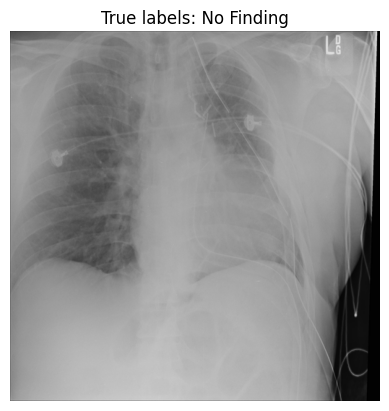

,Disease,Probability,Threshold,Detected
0,Emphysema,0.632,0.604,True
1,No Finding,0.583,0.269,True
2,Nodule,0.538,0.502,True
3,Atelectasis,0.504,0.481,True
4,Mass,0.483,0.534,False
5,Infiltration,0.464,0.418,True
6,Consolidation,0.443,0.463,False
7,Pneumothorax,0.436,0.512,False
8,Edema,0.354,0.470,False
9,Effusion,0.262,0.475,False


In [15]:
def predict_image(path, model, config):
    img = tf.image.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, [config["img_size"], config["img_size"]]) / 255.0
    prob = model.predict(img[None, ...], verbose=0)[0]
    out = pd.DataFrame({"Disease": config["classes"], "Probability": prob, "Threshold": config["thresholds"]})
    out["Detected"] = out["Probability"] >= out["Threshold"]
    return out.sort_values("Probability", ascending=False).reset_index(drop=True)

sample = test_df.sample(1, random_state=7).iloc[0]
plt.imshow(plt.imread(sample["image_path"]), cmap="gray"); plt.axis("off")
plt.title("True labels: " + ", ".join(sample["labels_list"])); plt.show()
display(predict_image(sample["image_path"], model, config).round(3))